# FPL's public day-ahead load forecast: alignment and a fair benchmark

Florida Power & Light reports its hourly load and its own day-ahead load forecast to the EIA (form EIA-930). The questions:

1. What does FPL's load look like, and is the public data clean?
2. How accurate is FPL's day-ahead forecast, and where does it miss?
3. How much does a backtest flatter itself if it uses observed weather instead of the weather forecast that existed at the time?
4. How does a simple, honest model compare with FPL's forecast on the same hours?

Data: EIA-930 (FPL demand and day-ahead forecast), observed temperatures at 7 FPL-territory airports (Iowa State ASOS archive), and GFS temperature forecasts made about a day ahead (Open-Meteo Previous Runs). Jan 2024 to Nov 2026, all in UTC, hour-ending.

Functions are in `../src/fpl.py`; the download is `../src/fpl_data.py`.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import fpl

PATH = "../data/fpl/fpl_hourly.parquet"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
if not os.path.exists(PATH):
    raise SystemExit("Run the download first, from the repo root: EIA_API_KEY=... python -m src.fpl_data")

INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.width", 140)

## 1. Audit before anything else

In [2]:
raw = pd.read_parquet(PATH)
print(f"{len(raw):,} hours; missing load: {raw['load_mw'].isna().sum()}")
raw[["load_mw", "fpl_df_mw", "temp_obs_f", "temp_fc_f"] + [f"obs_{s}" for s in fpl.STATIONS]].describe().T[["count", "min", "max"]]

25,032 hours; missing load: 49


,count,min,max
load_mw,24983.0,39.000000,32218.000000
fpl_df_mw,24957.0,8918.000000,30158.000000
temp_obs_f,25023.0,30.833333,94.833333
temp_fc_f,24588.0,30.414286,94.300000
obs_MIA,25001.0,35.000000,99.000000
obs_FLL,25003.0,35.000000,97.000000
obs_PBI,0.0,NaN,NaN
obs_RSW,23747.0,0.000000,98.000000
obs_SRQ,24609.0,-73.000000,99.000000
obs_DAB,24995.0,23.000000,97.000000


Before quoting any number, look at the extremes. The load minimum (39 MW) is impossible for a utility this size, and Sarasota at −73 °F didn't happen. The 32,218 MW maximum *looks* like a record, but it isn't one: it's a one-hour spike at midnight, with neighbors around 12,300 MW. West Palm Beach (PBI) returned no observations at all.

`clean` flags load more than 25% away from the median of its neighbors (or below 5,000 MW), and temperatures outside 15-105 °F or more than 15 °F from the same station's nearby hours. It prints what it flags so I can check it before anything is removed. Stations without observations are dropped from *both* temperature averages, so observed and forecast describe the same places.

In [3]:
df = fpl.clean(raw)
local = df.tz_convert("America/New_York")      # Eastern time, for reading results by local hour

load glitches:
                           load_mw
hour_end_utc                      
2024-02-01 05:00:00+00:00  32218.0
2024-03-10 00:00:00+00:00     39.0
2024-10-02 04:00:00+00:00  29545.0
2025-04-27 14:00:00+00:00   2259.0
2026-09-12 04:00:00+00:00    666.0
bad temperature readings per station: {'obs_RSW': 2, 'obs_SRQ': 6}
stations with no observations, dropped from both averages: ['PBI']


**The real peak.** After cleaning, FPL's highest hours were summer afternoons in August 2026. The February 2026 cold snap didn't make the top five.

In [4]:
local["load_mw"].nlargest(5)

hour_end_utc
2026-08-17 17:00:00-04:00    29959.0
2026-08-18 17:00:00-04:00    29873.0
2026-08-18 18:00:00-04:00    29719.0
2026-08-18 16:00:00-04:00    29676.0
2026-08-17 16:00:00-04:00    29575.0
Name: load_mw, dtype: float64

**The temperature forecasts run cool.** Day-ahead forecasts are colder than observed at every station, most along the southeast coast and least in Pensacola. The bias is largest at night, which fits airports sitting in warm cities while a model grid cell averages in cooler land and sea. So a bias correction should depend on the hour, not be one number.

In [5]:
by_station = pd.Series({s: (local[f"fc_{s}"] - local[f"obs_{s}"]).mean() for s in fpl.STATIONS
                        if local[f"obs_{s}"].notna().any()}, name="forecast minus observed (F)")
by_hour = (local["temp_fc_f"] - local["temp_obs_f"]).groupby(local.index.hour).mean()
print(by_station.round(1).to_string())
print("\nby local hour:", by_hour.round(1).to_dict())

MIA   -2.7
FLL   -2.4
RSW   -1.2
SRQ   -2.2
DAB   -1.3
PNS   -0.7

by local hour: {0: -2.3, 1: -2.3, 2: -2.2, 3: -2.1, 4: -2.1, 5: -2.1, 6: -2.2, 7: -2.3, 8: -1.5, 9: -1.1, 10: -1.2, 11: -1.3, 12: -1.3, 13: -1.1, 14: -0.9, 15: -0.9, 16: -1.1, 17: -1.3, 18: -1.7, 19: -1.9, 20: -2.1, 21: -2.2, 22: -2.3, 23: -2.4}


## 2. FPL's forecast: a pattern that looks like timing

Score the forecast as published: error = forecast − actual, so positive means FPL forecast too much.

In [6]:
err_raw = local["fpl_df_mw"] - local["load_mw"]
print(fpl.score(err_raw, local["load_mw"]).round(2).to_dict())
fpl.score_by(err_raw, local["load_mw"], local.index.hour).round(1).T

{'hours': 24903.0, 'MAPE_%': 3.21, 'bias_MW': 98.61}


key,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
hours,1032.0,1044.0,1035.0,1037.0,1035.0,1038.0,1038.0,1038.0,1038.0,1038.0,...,1038.0,1038.0,1038.0,1038.0,1038.0,1037.0,1038.0,1038.0,1038.0,1038.0
MAPE_%,4.2,3.3,2.6,1.8,1.7,1.9,3.2,3.0,3.6,4.3,...,3.2,3.3,3.3,3.4,3.5,3.3,3.1,3.0,3.4,4.0
bias_MW,-578.0,-390.6,-260.9,-167.2,-88.8,59.0,331.2,316.1,464.7,609.1,...,414.4,324.8,226.5,143.8,140.9,-41.6,-93.4,-177.4,-406.4,-563.6


The bias by hour isn't random. It runs high while load is rising (morning to afternoon) and low while it falls (evening and night). That's the fingerprint of a timing offset: a forecast that's slightly *ahead* of the actuals reads high on the way up and low on the way down.

**First guess: a one-hour offset, maybe daylight saving.** Test it, along with the controls:

In [7]:
tests = fpl.alignment_tests(local["fpl_df_mw"], local["load_mw"])
tests.round(2)

as reported             3.21
moved 1 h later         3.70
moved 1 h earlier       7.12
moved 30 min later      2.40
moved 30 min earlier    5.00
smoothed, no shift      3.18
Name: MAPE_%, dtype: float64

- **Not a one-hour offset.** The forecast as reported beats either one-hour shift.
- **But the two directions are lopsided.** An hour later costs about half a point, an hour earlier more than doubles the error. A forecast with no timing quirk would be hurt about equally either way, so this one leads the actuals by *less* than an hour.
- **Moving it 30 minutes later cuts MAPE from 3.21% to 2.40%.**
- **The controls rule out smoothing.** Averaging two hours also smooths, but smoothing alone (3.18%) barely helps, and moving it 30 minutes the wrong way makes it worse (5.00%).

The likely cause is a definition difference: for example, actual load as an average over the hour, and the forecast as a value at the hour mark. Only FPL or EIA could confirm which. Before judging any forecast, check that it and the actuals mean the same thing by "this hour".

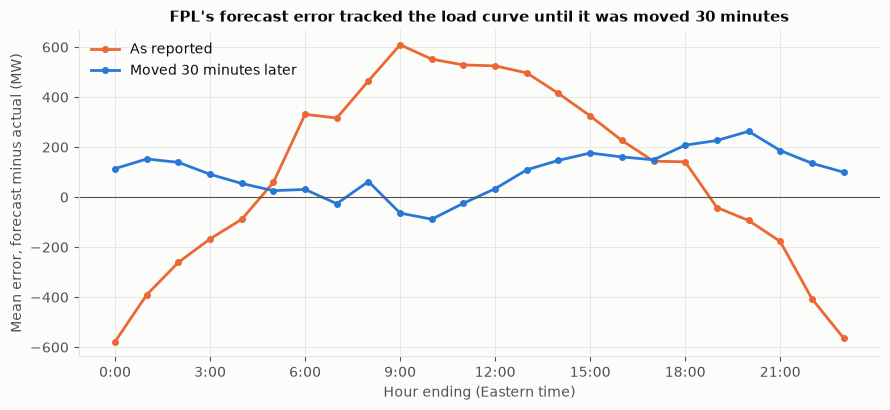

In [8]:
local["fpl_df_aligned"] = fpl.shifted_half_hour(local["fpl_df_mw"], "later")
err = local["fpl_df_aligned"] - local["load_mw"]

bias_raw = err_raw.groupby(local.index.hour).mean()
bias_aligned = err.groupby(local.index.hour).mean()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(bias_raw.index, bias_raw, color=ORANGE, lw=2, marker="o", ms=4, label="As reported")
ax.plot(bias_aligned.index, bias_aligned, color=BLUE, lw=2, marker="o", ms=4, label="Moved 30 minutes later")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
ax.set_xlabel("Hour ending (Eastern time)")
ax.set_ylabel("Mean error, forecast minus actual (MW)")
ax.legend(loc="upper left")
ax.set_title("FPL's forecast error tracked the load curve until it was moved 30 minutes")
fig.tight_layout()
fig.savefig(f"{FIG}/alignment.png", dpi=150)
plt.show()

## 3. FPL's aligned forecast, by slice

In [9]:
print(fpl.score(err, local["load_mw"]).round(2).to_dict())
fpl.score_by(err, local["load_mw"], local.index.month).round(1).T

{'hours': 24893.0, 'MAPE_%': 2.4, 'bias_MW': 98.37}


key,1,2,3,4,5,6,7,8,9,10,11,12
hours,2232.0,2039.0,2215.0,2159.0,2208.0,2136.0,2232.0,2232.0,2159.0,2231.0,1558.0,1492.0
MAPE_%,2.7,2.6,2.6,2.0,2.0,2.4,2.2,2.5,2.5,2.4,2.5,2.5
bias_MW,18.2,200.4,252.7,98.5,152.2,186.7,61.1,143.1,-131.3,-13.6,153.7,74.2


In [10]:
bands = fpl.score_by(err, local["load_mw"], fpl.temp_band(local["temp_obs_f"]))
bands.round(1)

,hours,MAPE_%,bias_MW
key,,,
<45,180.0,3.5,-310.5
45-55,935.0,2.8,-6.8
55-65,2730.0,2.7,168.7
65-75,6652.0,2.3,148.9
75-85,11299.0,2.4,127.8
85+,3089.0,2.2,-125.6


Temperature bands use *observed* temperature. That's fine here: this diagnoses FPL's forecast after the fact, it isn't an input to one.

FPL **under-forecasts both extremes and over-forecasts mild weather.** That's what a temperature response that's slightly too flat at the tails looks like. The coldest band is only 180 hours, mostly one cold snap, so it's a strong hint rather than proof.

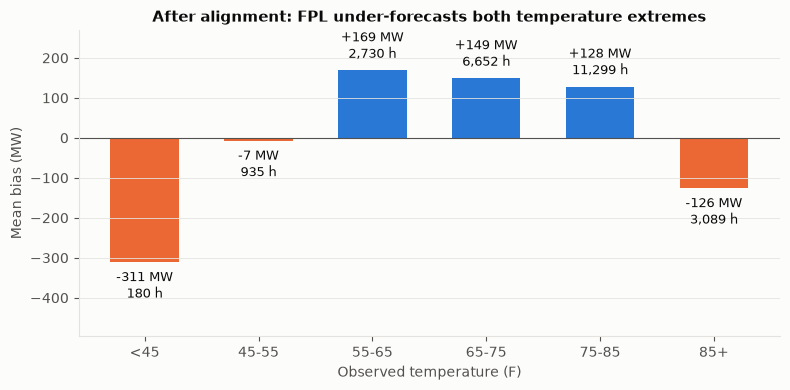

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [ORANGE if v < 0 else BLUE for v in bands["bias_MW"]]
bars = ax.bar(bands.index.astype(str), bands["bias_MW"], color=colors, width=0.6)
for b, (lbl, row) in zip(bars, bands.iterrows()):
    y = row["bias_MW"]
    ax.annotate(f"{y:+.0f} MW\n{int(row['hours']):,} h", (b.get_x() + b.get_width() / 2, y),
                xytext=(0, 6 if y >= 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if y >= 0 else "top", fontsize=9, color=INK)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_ylim(bands["bias_MW"].min() * 1.6, bands["bias_MW"].max() * 1.6)
ax.set_xlabel("Observed temperature (F)")
ax.set_ylabel("Mean bias (MW)")
ax.grid(axis="x", visible=False)
ax.set_title("After alignment: FPL under-forecasts both temperature extremes")
fig.tight_layout()
fig.savefig(f"{FIG}/bias_by_temperature.png", dpi=150)
plt.show()

## 4. The fairness trap: observed vs. forecast weather

One simple model, fit separately for each local hour of the day: temperature hinges for heating and cooling, day of week, holidays, a growth trend, and load from 48 and 168 hours earlier (both known when a day-ahead forecast is made). Train on 2024-2025, test on 2026, three ways:

| Run | Trained on | Tested with | What it represents |
|---|---|---|---|
| A | observed temps | observed temps | the flattering backtest |
| B | observed temps | forecast temps | a naive pipeline going live |
| C | forecast temps | forecast temps | the honest setup |

In [12]:
runs = {"A: observed in, observed out": ("temp_obs_f", "temp_obs_f"),
        "B: observed in, forecast out": ("temp_obs_f", "temp_fc_f"),
        "C: forecast in, forecast out": ("temp_fc_f", "temp_fc_f")}
preds = {name: fpl.fit_predict(local, a, b) for name, (a, b) in runs.items()}
common = pd.concat(preds, axis=1).dropna().index            # score all three on the same hours
fair = pd.Series({name: fpl.ape(p[common], local.loc[common, "load_mw"]).mean() for name, p in preds.items()},
                 name="2026 MAPE %")
fair.round(2)

A: observed in, observed out    3.87
B: observed in, forecast out    5.34
C: forecast in, forecast out    4.21
Name: 2026 MAPE %, dtype: float64

- **Observed weather flatters the backtest by about 9%** (A vs. C). In my ERCOT project the same gap was 19%; Florida's weather is milder and easier to forecast a day ahead.
- **The naive pipeline is the real danger** (B, 38% worse than A). A model trained on observed temperatures never learns that forecasts run about 2 °F cool, so it under-predicts cooling load every day. Training on forecasts lets the model absorb that bias. Train on what you'll actually have at forecast time.

## 5. A fair benchmark: same hours, same rules

FPL's aligned forecast, my honest model (C), and a naive baseline (same hour last week), scored on exactly the same 2026 hours. Skill is the reduction in squared error relative to the baseline.

In [13]:
table, n = fpl.benchmark({"FPL day-ahead (aligned)": local["fpl_df_aligned"],
                          "Honest model (C)": preds["C: forecast in, forecast out"],
                          "Same hour last week": local["load_mw"].shift(168)},
                         local.loc[common, "load_mw"], "Same hour last week")
print(f"{n:,} hours in 2026")
table.round(2)

7,446 hours in 2026


,MAPE_%,bias_MW,skill vs Same hour last week (%)
FPL day-ahead (aligned),2.53,84.84,91.75
Honest model (C),4.19,0.47,81.02
Same hour last week,9.55,-63.16,0.00


- **FPL's forecast is excellent:** 2.53% MAPE and 92% skill over the baseline.
- **The honest model is solid but simple:** 4.19% and 81% skill, and essentially unbiased, while FPL runs about +85 MW high.
- **The gap is mostly the model, not the weather.** Even with perfect weather (run A, 3.87%) the simple model trails FPL. FPL likely uses more stations, humidity and cloud cover, several weather providers, and updates up to submission. Cheap next steps would be humidity (heat index) and blending a second weather model.

## Summary

| Question | Answer |
|---|---|
| Is the public data clean? | Mostly. 49 missing hours, 5 one-hour load glitches (including a 32,218 MW spike that looks like a record), 8 bad airport readings, and one station with no data. |
| How good is FPL's forecast? | 3.21% as published, but most of the gap to 2.40% was a ~30-minute convention difference, confirmed with controls. Aligned, it's 2.53% in 2026. |
| Where does it miss? | Late afternoon and evening, and at both temperature extremes (−311 MW below 45 °F, −126 MW above 85 °F). |
| How much does observed weather flatter a backtest? | About 9% here. Training on observed and running on forecasts is 38% worse. |
| Honest model vs. FPL? | 4.19% vs. 2.53% on the same hours; the gap is mostly model richness, not weather. |